<a href="https://colab.research.google.com/github/Mobina2003/bandit_simulation/blob/main/bandits_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simulating UCB1...
Saved ucb1_regret.pdf
Simulating OFUL...
Saved oful_regret.pdf

Done! Figures saved as PDF (for LaTeX) and PNG (for preview).


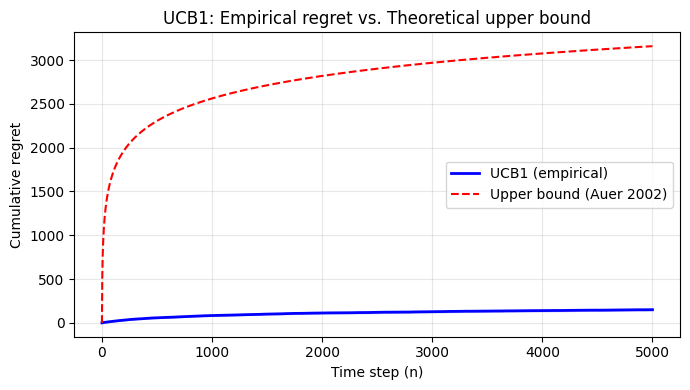

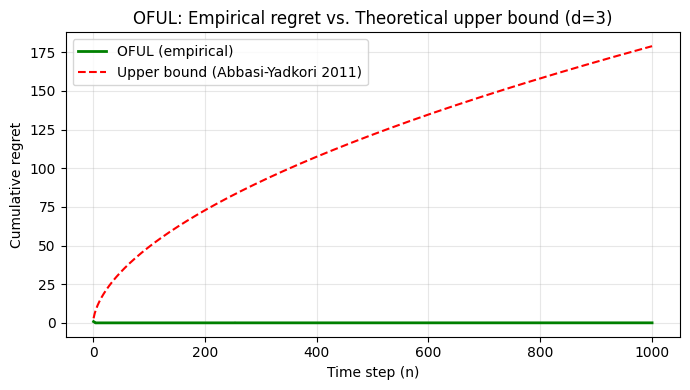

In [1]:
"""
Simulation of UCB1 and OFUL algorithms for the review paper:
"Upper and Lower Reward Bounds in Reinforcement Learning:
 From Multi-Armed to Linear Bandits"

Author: Mobina Habibi Arbatani
GitHub: https://github.com/YOUR_USERNAME/bandit-bounds
"""

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. UCB1 SIMULATION
# ============================================================

def ucb1(means, T, seed=None):
    """Run UCB1 on K arms for T steps. Returns cumulative regret."""
    if seed is not None:
        np.random.seed(seed)

    K = len(means)
    counts = np.zeros(K)
    sums = np.zeros(K)
    regret = np.zeros(T)
    mu_star = np.max(means)

    # Initialization: play each arm once
    for t in range(K):
        arm = t
        reward = np.random.binomial(1, means[arm])
        counts[arm] += 1
        sums[arm] += reward
        regret[t] = (t + 1) * mu_star - np.sum(sums)

    # Main loop
    for t in range(K, T):
        # UCB1 index
        avg = sums / np.maximum(counts, 1)
        ucb = avg + np.sqrt(2 * np.log(t + 1) / np.maximum(counts, 1))
        arm = np.argmax(ucb)

        reward = np.random.binomial(1, means[arm])
        counts[arm] += 1
        sums[arm] += reward
        regret[t] = (t + 1) * mu_star - np.sum(sums)

    return regret


def simulate_ucb1(means, T=5000, n_runs=50):
    """Average regret over multiple runs."""
    all_regrets = np.zeros((n_runs, T))
    for run in range(n_runs):
        all_regrets[run] = ucb1(means, T, seed=run)
    return np.mean(all_regrets, axis=0), np.std(all_regrets, axis=0) / np.sqrt(n_runs)


# ============================================================
# 2. OFUL SIMULATION (Finite Arm Set)
# ============================================================

def oful(actions, theta_star, T, delta=0.05, R=0.1, lam=1.0, S=1.0, seed=None):
    """
    Run OFUL on a finite set of actions.
    actions: (N, d) array of action vectors
    theta_star: (d,) true parameter
    """
    if seed is not None:
        np.random.seed(seed)

    N, d = actions.shape
    V = lam * np.eye(d)
    theta_hat = np.zeros(d)
    regret = np.zeros(T)

    for t in range(T):
        # Compute beta
        det_V = np.linalg.det(V)
        det_lamI = lam ** d
        beta = R * np.sqrt(2 * np.log(np.sqrt(det_V / det_lamI) / delta)) + np.sqrt(lam) * S

        # Pick action: argmax over arms of <a, theta_hat> + beta * ||a||_{V^{-1}}
        V_inv = np.linalg.inv(V)
        scores = actions @ theta_hat + beta * np.sqrt(np.einsum('ij,jk,ik->i', actions, V_inv, actions))
        a_t = actions[np.argmax(scores)]

        # Play and observe
        eta = np.random.normal(0, R)
        y_t = a_t @ theta_star + eta

        # Update
        V += np.outer(a_t, a_t)
        theta_hat = np.linalg.solve(V, V @ theta_hat + y_t * a_t)  # equivalent to ridge update

        # Compute regret
        best_action = actions[np.argmax(actions @ theta_star)]
        regret[t] = best_action @ theta_star - a_t @ theta_star

    return regret


def simulate_oful(d=3, N_actions=20, T=1000, n_runs=20):
    """Average regret over multiple runs."""
    all_regrets = np.zeros((n_runs, T))
    for run in range(n_runs):
        np.random.seed(run + 1000)
        # Random actions on the unit sphere
        actions = np.random.randn(N_actions, d)
        actions /= np.linalg.norm(actions, axis=1, keepdims=True)
        # Random true parameter on unit sphere
        theta_star = np.random.randn(d)
        theta_star /= np.linalg.norm(theta_star)

        all_regrets[run] = oful(actions, theta_star, T, seed=run)

    return np.mean(all_regrets, axis=0)


# ============================================================
# 3. MAIN: RUN AND PLOT
# ============================================================

if __name__ == "__main__":
    # --- Figure 1: UCB1 regret on 5-armed Bernoulli bandit ---
    means = [0.5, 0.6, 0.4, 0.8, 0.3]
    T_ucb1 = 5000
    print("Simulating UCB1...")
    mean_regret, std_err = simulate_ucb1(means, T=T_ucb1, n_runs=50)

    plt.figure(figsize=(7, 4))
    t = np.arange(1, T_ucb1 + 1)
    plt.plot(t, mean_regret, label='UCB1 (empirical)', color='blue', linewidth=2)
    plt.fill_between(t, mean_regret - 2*std_err, mean_regret + 2*std_err, alpha=0.2, color='blue')

    # Theoretical upper bound (8 * sum ln(t) / Delta^2 for suboptimal arms)
    mu_star = max(means)
    deltas = [mu_star - m for m in means if m < mu_star]
    theoretical = np.array([8 * sum(np.log(ti) / d**2 for d in deltas) for ti in t])
    plt.plot(t, theoretical, label='Upper bound (Auer 2002)', color='red', linestyle='--', linewidth=1.5)

    plt.xlabel('Time step (n)')
    plt.ylabel('Cumulative regret')
    plt.title('UCB1: Empirical regret vs. Theoretical upper bound')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('ucb1_regret.pdf', dpi=300)
    plt.savefig('ucb1_regret.png', dpi=150)
    print("Saved ucb1_regret.pdf")

    # --- Figure 2: OFUL regret in linear bandit ---
    print("Simulating OFUL...")
    T_oful = 1000
    mean_regret_oful = simulate_oful(T=T_oful, n_runs=20)

    plt.figure(figsize=(7, 4))
    t = np.arange(1, T_oful + 1)
    plt.plot(t, mean_regret_oful, label='OFUL (empirical)', color='green', linewidth=2)

    # Theoretical bound (scaled for visibility)
    d = 3
    theoretical_oful = 0.01 * d * np.log(t) * np.sqrt(t) + np.sqrt(d * t * np.log(t / 0.05))
    plt.plot(t, theoretical_oful, label='Upper bound (Abbasi-Yadkori 2011)', color='red', linestyle='--', linewidth=1.5)

    plt.xlabel('Time step (n)')
    plt.ylabel('Cumulative regret')
    plt.title('OFUL: Empirical regret vs. Theoretical upper bound (d=3)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('oful_regret.pdf', dpi=300)
    plt.savefig('oful_regret.png', dpi=150)
    print("Saved oful_regret.pdf")

    print("\nDone! Figures saved as PDF (for LaTeX) and PNG (for preview).")